# 05 · Analyse des erreurs

Où le modèle se trompe encore, pourquoi les corrections après prédiction marchent, ce qui n'a pas marché, et dans quelle mesure on peut se fier au score local. Ce notebook ne fait que relire les résultats des notebooks 02 à 04.

In [1]:
"""Compatibilité avec les résultats existants et libellés de présentation.

Les valeurs historiques ci-dessous sont volontairement conservées : elles déterminent
les clés JSON, les noms de caches et leur ordre. Le code de calcul utilise les noms
explicites des constantes ; seules des copies destinées à l’affichage sont traduites.
"""

BLOCK_RECORDING_PRECISION = 'P'
BLOCK_TRAVEL = 'T'
BLOCK_MEET_CONTEXT = 'M'
BLOCK_EXTENDED_MEET_CONTEXT = 'M2'
BLOCK_DIVISION_CONTEXT = 'D'
BLOCK_ATHLETE_HISTORY = 'H'
BLOCK_DOTS_SCALE = 'S'
BLOCK_PROXY_IDENTIFIERS = 'C'
BLOCK_ATHLETE_CAREER = 'H2'
BLOCK_MEET_EXPERIENCE = 'E'
BLOCK_MODEL_SPECIFIC = 'PM'
BLOCK_ATHLETE_PERFORMANCE = 'AS'
BLOCK_MEET_PERFORMANCE = 'MS'
VARIANT_WEIGHT_CLASS_BASELINE = 'F0'
VARIANT_PRECISION_AND_TRAVEL = 'PT'
VARIANT_CONTEXT_COMBINED = 'ALL'
VARIANT_CONTEXT_BASELINE = 'R1'
VARIANT_HISTORY_COMBINED = 'ALL2'
VARIANT_HISTORY_BASELINE = 'R2'
VARIANT_FINAL_FEATURES = 'ALL3'
VARIANT_FINAL_BASELINE = 'R3'
VARIANT_PERFORMANCE_COMBINED = 'ALL4'
CATBOOST_DEPTH8_BASELINE = 'C1'
CATBOOST_DEPTH8_REGULARIZED = 'C2'
CATBOOST_DEPTH6_REGULARIZED = 'C3'
MODEL_LIGHTGBM = 'lgb'
MODEL_XGBOOST = 'xgb'
MODEL_CATBOOST_ABSOLUTE = 'catboost'
MODEL_LIGHTGBM_DOTS = 'lgb_rel'
MODEL_CATBOOST_DOTS = 'cb_rel'
MODEL_CATBOOST_IPF_GL = 'cb_gl'
MODEL_CATBOOST_ALLOMETRIC = 'cb_allo'
MODEL_HISTOGRAM_GRADIENT_BOOSTING = 'hgb'
MODEL_EXTRA_TREES = 'et'
MODEL_RANDOM_FOREST = 'rf'
MATCH_RESIDENCE = 'A0'
MATCH_FEDERATION = 'A1'
MATCH_EQUIPMENT = 'A2'
MATCH_WEIGHT_CLASS = 'A3'
MATCH_MEET = 'M2'
SMOOTHING_EXACT_BIRTHYEAR = 'S0_exact'
SMOOTHING_NEARBY_BIRTHYEAR = 'S1_fuzzy'
SMOOTHING_TEMPORAL = 'S2_decay'
SMOOTHING_COMBINED_LINEAR = 'S3_all_linear'
SMOOTHING_COMBINED_BOOSTING = 'S4_all_gbm'
CACHE_CONTEXT_ABLATION = 'round1'
CACHE_HISTORY_ABLATION = 'round2'
CACHE_CAREER_ABLATION = 'round3'
CACHE_PERFORMANCE_ABLATION = 'round4'
CACHE_SIX_MODEL_ENSEMBLE = 'v1_six_models'
CACHE_EXPANDED_SEED_ENSEMBLE = 'v2_more_seeds'
CACHE_FINAL_ENSEMBLE = 'v4_eight_models'
CACHE_INITIAL_ENSEMBLE = 'baseline_v1'
CACHE_TEN_FOLD_ENSEMBLE = 'baseline_v2'
ENSEMBLE_INITIAL = 'v1'
ENSEMBLE_TEN_FOLD = 'v2'
ENSEMBLE_WITH_HISTOGRAM_BOOSTING = 'v3_plus'
ENSEMBLE_FINAL = 'v4'
MODEL_CATBOOST_DEPTH8_BASELINE = 'catboost_C1'
CONFIG_PURPOSE_CONTEXT_ABLATION = 'feature round 1 (P/T/M blocks); inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_HISTORY_ABLATION = 'feature round 2 on top of 07 ALL; inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_CAREER_ABLATION = 'feature round 3 on top of 09 ALL2; inner 10% early stop, score early-stopped model on outer fold'
MODEL_CATBOOST_DEPTH8_REGULARIZED = 'catboost_C2'
MODEL_CATBOOST_DEPTH6_REGULARIZED = 'catboost_C3'
CONFIG_PURPOSE_MODEL_COMPARISON = 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold'

CACHE_CATBOOST_IPF_GL_BASELINE_STEM = 'cb_gl__R3'
CACHE_CATBOOST_IPF_GL_SEED42_STEM = 'cb_gl__s42'
MODEL_CATBOOST_PREFIX = 'cb_'
MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE = 'cb_rel_lr03'
CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE = 'final ensemble: ALL3 per-model features, 5-fold x seeds, inner 10% early stop, full refit'
SUMMARY_RESIDUAL_SMOOTHING = '+S3'
SUMMARY_FINAL_SMOOTHING = '+ S3 smoothing (cross-fitted coefficients)'
SUMMARY_FINAL_CANDIDATES = '+ HGB + cb_gl (final)'
SUBMISSION_FINAL_BASE_FILENAME = 'submission_final_v4_base.csv'
SUBMISSION_FINAL_FILENAME = 'submission_final_v4_final.csv'

LEGACY_SUMMARY_COMBINED_SMOOTHING = '+ S3 \u5e73\u6ed1\uff08\u4ea4\u53c9\u62df\u5408\uff09'
HISTORY_TEN_FOLD_MATCHING = 'v2 + twins'
HISTORY_WEIGHT_CLASS_MATCHING = '07 F0 + twins'
HISTORY_CONTEXT_REGULARIZED = '07 ALL + C2'
HISTORY_CONTEXT_REGULARIZED_MATCHING = '07 ALL + C2 + twins'
HISTORY_MODEL_STACKING = '08 stack'
HISTORY_STACKING_MATCHING = '08 + twins'
HISTORY_STACKING_RESIDUAL_SMOOTHING = '08 + twins + athlete'
HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING = 'v2 + twins + athlete'
HISTORY_FINAL_FEATURES_MATCHING = '10 ALL3 + twins'
HISTORY_EXACT_BIRTHYEAR_SMOOTHING = '10 + S0'
HISTORY_COMBINED_RESIDUAL_SMOOTHING = '10 + S3'
HISTORY_SIX_MODEL_FOLD_AVERAGE = '11 fold average'
HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE = '13 v3_plus'
HISTORY_FINAL_FEATURES_REFERENCE = '14 R3'
HISTORY_ATHLETE_PERFORMANCE = '14 AS'
HISTORY_FINAL_ENSEMBLE = '15 v4 (final)'


PRESENTATION_LABELS = {
    HISTORY_TEN_FOLD_MATCHING: 'v2 + jumelles',
    HISTORY_WEIGHT_CLASS_MATCHING: 'variables de départ + jumelles',
    HISTORY_CONTEXT_REGULARIZED: 'série 1 + CatBoost régularisé',
    HISTORY_CONTEXT_REGULARIZED_MATCHING: 'série 1 + CatBoost régularisé + jumelles',
    HISTORY_MODEL_STACKING: 'exp. 08 : plus de modèles',
    HISTORY_STACKING_MATCHING: 'exp. 08 + jumelles',
    HISTORY_STACKING_RESIDUAL_SMOOTHING: 'exp. 08 + jumelles + lissage',
    HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING: 'v2 + jumelles + lissage',
    HISTORY_FINAL_FEATURES_MATCHING: 'série 3 + jumelles',
    HISTORY_EXACT_BIRTHYEAR_SMOOTHING: 'série 3 + lissage (même année)',
    HISTORY_COMBINED_RESIDUAL_SMOOTHING: 'série 3 + lissage combiné',
    HISTORY_SIX_MODEL_FOLD_AVERAGE: 'six modèles, moyenne des plis',
    HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE: 'six modèles + HGB',
    HISTORY_FINAL_FEATURES_REFERENCE: 'référence de la série 4',
    HISTORY_ATHLETE_PERFORMANCE: 'niveau du sportif',
    HISTORY_FINAL_ENSEMBLE: 'huit modèles',
    '+ HGB + cb_gl (final, exp. 15)': '+ HGB + CatBoost IPF GL (exp. 15)',
    BLOCK_RECORDING_PRECISION: 'Précision',
    BLOCK_TRAVEL: 'Déplacements',
    BLOCK_MEET_CONTEXT: 'Contexte',
    BLOCK_EXTENDED_MEET_CONTEXT: 'Contexte enrichi',
    BLOCK_DIVISION_CONTEXT: 'Divisions',
    BLOCK_ATHLETE_HISTORY: 'Historique',
    BLOCK_DOTS_SCALE: 'Coefficient DOTS',
    BLOCK_PROXY_IDENTIFIERS: 'Identifiants',
    BLOCK_ATHLETE_CAREER: 'Carrière',
    BLOCK_MEET_EXPERIENCE: 'Expérience du plateau',
    BLOCK_MODEL_SPECIFIC: 'Ajouts par modèle',
    BLOCK_ATHLETE_PERFORMANCE: 'Niveau du sportif',
    BLOCK_MEET_PERFORMANCE: 'Niveau de la compétition',
    VARIANT_WEIGHT_CLASS_BASELINE: 'Départ',
    VARIANT_PRECISION_AND_TRAVEL: 'Précision + déplacements',
    VARIANT_CONTEXT_COMBINED: 'Série 1 complète',
    VARIANT_CONTEXT_BASELINE: 'Référence série 2',
    VARIANT_HISTORY_COMBINED: 'Série 2 retenue',
    VARIANT_HISTORY_BASELINE: 'Référence série 3',
    VARIANT_FINAL_FEATURES: 'Variables finales',
    VARIANT_FINAL_BASELINE: 'Référence série 4',
    VARIANT_PERFORMANCE_COMBINED: 'Niveaux combinés',
    CATBOOST_DEPTH8_BASELINE: 'prof. 8, L2 3',
    CATBOOST_DEPTH8_REGULARIZED: 'prof. 8, L2 10',
    CATBOOST_DEPTH6_REGULARIZED: 'prof. 6, L2 10',
    MODEL_CATBOOST_DOTS: 'CatBoost DOTS',
    MODEL_LIGHTGBM_DOTS: 'LightGBM DOTS',
    MODEL_CATBOOST_IPF_GL: 'CatBoost IPF GL',
    MODEL_CATBOOST_ALLOMETRIC: 'CatBoost allométrique',
    MODEL_LIGHTGBM: 'LightGBM',
    MODEL_XGBOOST: 'XGBoost',
    MODEL_CATBOOST_ABSOLUTE: 'CatBoost',
    MODEL_HISTOGRAM_GRADIENT_BOOSTING: 'HGB',
    MODEL_EXTRA_TREES: 'ExtraTrees',
    MODEL_RANDOM_FOREST: 'Forêt aléatoire',
    MATCH_RESIDENCE: 'Clé 1 :',
    MATCH_FEDERATION: 'Clé 2 :',
    MATCH_EQUIPMENT: 'Clé 3 :',
    MATCH_WEIGHT_CLASS: 'Clé 4 :',
    'S0': 'même année',
    'S1': 'année ±1',
    'S2': 'pondération temporelle',
    'S3': 'lissage combiné',
    'S4': 'lissage LightGBM',
    ENSEMBLE_INITIAL: 'v1',
    ENSEMBLE_TEN_FOLD: 'v2',
    ENSEMBLE_WITH_HISTOGRAM_BOOSTING: 'six modèles + HGB',
    ENSEMBLE_FINAL: 'huit modèles',
    SMOOTHING_EXACT_BIRTHYEAR: 'Même année',
    SMOOTHING_NEARBY_BIRTHYEAR: 'Année ±1',
    SMOOTHING_TEMPORAL: 'Pondération temporelle',
    SMOOTHING_COMBINED_LINEAR: 'Combinaison linéaire',
    SMOOTHING_COMBINED_BOOSTING: 'Combinaison par LightGBM',
}


def presentation_label(value):
    """Traduire un libellé d’expérience sans toucher à sa valeur de calcul."""
    if isinstance(value, tuple):
        return tuple(presentation_label(part) for part in value)
    if not isinstance(value, str):
        return value
    if '|' in value:
        return value
    if value in PRESENTATION_LABELS:
        return PRESENTATION_LABELS[value]
    import re
    if value.endswith(('.csv', '.npz', '.npy', '.json')):
        return value
    keys = [key for key in PRESENTATION_LABELS if key not in (MODEL_EXTRA_TREES, MODEL_RANDOM_FOREST)]
    pattern = r'(?<![A-Za-z0-9_])(' + '|'.join(re.escape(key) for key in sorted(keys, key=len, reverse=True)) + r')(?![A-Za-z0-9_])'
    return re.sub(pattern, lambda match: PRESENTATION_LABELS[match.group()], value)


def presentation_copy(value):
    """Traduire uniquement les libellés de synthèse, sur une copie du tableau."""
    if 'pd' in globals() and isinstance(value, (pd.DataFrame, pd.Series)):
        shown = value.copy(deep=True)
        raw_columns = set(globals().get('RAW_FEATURES', []))
        label_fields = {'model', 'variant', 'tag', 'step', 'method', 'submission',
                        'params_key', 'feature', 'source', 'experiment', 'config',
                        'Ensemble', 'Modèle', 'Expérience', 'Clé'}
        # Un extrait des données conserve toutes ses valeurs et ses catégories.
        if isinstance(shown, pd.DataFrame) and raw_columns.intersection(shown.columns):
            return shown
        if isinstance(shown.index, pd.MultiIndex):
            names = shown.index.names
            shown.index = pd.MultiIndex.from_tuples(
                [tuple(presentation_label(part) if name in label_fields else part
                       for name, part in zip(names, row)) for row in shown.index], names=names)
        elif shown.index.name in label_fields:
            shown.index = shown.index.map(presentation_label)
        if isinstance(shown, pd.DataFrame):
            for column in shown.select_dtypes(include=['object', 'string']):
                if column in label_fields:
                    shown[column] = shown[column].map(presentation_label)
            # Les colonnes de modèles ou de variantes proviennent d’un pivot nommé.
            if shown.columns.name in label_fields:
                shown.columns = shown.columns.map(presentation_label)
        elif shown.name in label_fields and (shown.dtype == object or isinstance(shown.dtype, pd.StringDtype)):
            shown = shown.map(presentation_label)
        return shown
    if isinstance(value, dict):
        return {presentation_label(key): presentation_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [presentation_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple(presentation_copy(item) for item in value)
    return presentation_label(value)


def display(*values, **kwargs):
    """Afficher des libellés explicites sans modifier les tableaux de calcul."""
    return _display(*(presentation_copy(value) for value in values), **kwargs)


def print(*values, **kwargs):
    """Présenter les résumés textuels sans modifier les objets de calcul."""
    import builtins
    return builtins.print(*(presentation_copy(value) for value in values), **kwargs)

In [2]:
# Environnement, chemins et configuration communs aux cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # CSV sources, en lecture seule
ARTIFACTS = PROJECT_DIR / 'artifacts'           # Un sous-dossier de résultats par notebook
SEED = 42                                       # Cinq plis fixes : KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 10 % du train externe réservé à l’early stopping
MAX_ROUNDS = 20000
MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]             # Trois modèles pour les ablations, les plus rapides en premier
RUN_ONLY = None                                 # Liste de variantes à exécuter ; None = toutes
KEEP_DELTA = -0.05                              # kg : garder si ΔRMSE moyen ≤ −0.05 et amélioration sur ≥ 4/5 plis
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # Pas de bouton dans 01/05 ; 01 entraîne un petit HGB adversarial
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('Activer un seul entraînement à la fois ; redémarrer le runtime avant le suivant (variables partagées)')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """Préparer les dépendances et vérifier le GPU uniquement pour un entraînement."""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version(MODEL_CATBOOST_ABSOLUTE)
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if MODEL_CATBOOST_ABSOLUTE in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà importée ; redémarrer le runtime')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # Les autres modèles restent disponibles si cet import échoue
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version actuelle : {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('Un GPU est requis : choisir T4 GPU dans le type de runtime Colab, puis relancer')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {MODEL_CATBOOST_ABSOLUTE: catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('Versions    :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit indisponible, RealMLP / TabM seront ignorés :', PYTABKIT_ERROR)


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('Entraînements activés :', [k for k, v in TRAIN.items() if v])

Projet : performances-en-powerlifting
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


## 0. Données

In [3]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} differs from the original input; check the data file')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # Independent of object / str dtype (pandas 2 and 3).
require(train.shape == (105000, 18) and test.shape == (45000, 17), 'Unexpected data shape')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), 'Unexpected column groups')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), 'Unexpected missing values')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}; validation rows per fold: {np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17); validation rows per fold: [21000, 21000, 21000, 21000, 21000]


In [4]:
# Lecture des summary_*.csv et prédictions de plis ; aucun entraînement
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'Fichier absent : {path.relative_to(PROJECT_DIR)} ; synchroniser artifacts/ depuis Drive ou activer l’entraînement associé')
        return None
    table = pd.read_csv(path, index_col=index_col)
    # Traduire les anciens libellés en mémoire, sans modifier les caches CSV.
    label_map = {
        LEGACY_SUMMARY_COMBINED_SMOOTHING: '+ lissage combiné des résidus (coefficients croisés)',
        '+ \u53cc\u80de\u80ce\uff08\u4ea4\u53c9\u62df\u5408\uff09': '+ jumeaux (cross-fitting)',
        '+\u53cc\u80de\u80ce': '+matched',
        '08 \u4e94\u6298\u5806\u53e0\uff08global_nnls\uff09': '08 stacking, cinq plis (global_nnls)',
        '3 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '3 refits',
        '5 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '5 refits',
        '8 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '8 refits',
        'v2\uff0810 \u6298 \xd7 \u79cd\u5b50\uff0cNNLS\uff09': 'v2 (10 plis × graines, NNLS)',
        '\u500d\u6570': 'ratio',
        '\u540c\u4e00\u56fd\u5bb6': 'Même pays',
        '\u540c\u4e00\u573a\u6bd4\u8d5b': 'Même compétition',
        '\u540c\u4e00\u6bd4\u8d5b\u5e74\u4efd': 'Même année de compétition',
        '\u540c\u4e00\u8054\u76df': 'Même fédération',
        '\u6309 id \u6392\u5e8f': 'sorted_by_id',
        '\u6765\u6e90': 'source',
        '\u76f8\u90bb\u4e24\u884c': 'adjacent_rows',
        '\u878d\u5408\uff08\u5d4c\u5957\uff09': 'Ensemble (RMSE locale)',
        '\u968f\u673a\u987a\u5e8f': 'random_order',
    }
    table = table.rename(columns=label_map, index=label_map)
    for column in table.select_dtypes(include=['object', 'string']):
        table[column] = table[column].map(lambda value: label_map.get(value, value))
    return table


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """Comparaison appariée : barre = ΔRMSE moyen, points = plis, pointillé = seuil −0.05."""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([presentation_label(value) for value in rows.index.tolist()])
    ax.set_xlabel(f'Écart de RMSE par rapport à {presentation_label(baseline)} (kg) ; barres : moyenne, points : plis')
    ax.set_title(presentation_label(title))
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """Charger OOF et test moyen des cinq plis ; retourner None si un pli manque."""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

## 1. Résidus

Résidu = total réel − total prédit, en kg. On compare la combinaison des huit modèles et la même après jumelles et lissage par groupes (expérience 15, donc avant le lissage par paires).

RMSE locale : ensemble 76.319 → post-traitement 75.966


effectif  \
Groupe                                   Valeur                           
Sexe × équipement                        F|Multi-ply                380   
                                         F|Raw                    21755   
                                         F|Single-ply              6366   
                                         F|Unlimited                521   
                                         F|Wraps                   3515   
                                         Mx|Raw                       8   
                                         Mx|Wraps                     1   
                                         M|Multi-ply               2053   
                                         M|Raw                    43471   
                                         M|Single-ply             17352   
                                         M|Unlimited                545   
                                         M|Wraps                   9033   
Contrôle antidopage                      Untested                 24982   
                                         Yes                      80018   
Tranche d’âge                            [0.0, 18.0)              16274   
                                         [18.0, 24.0)             31485   
                                         [24.0, 35.0)             31720   
                                         [35.0, 40.0)              7594   
                                         [40.0, 50.0)             10191   
                                         [50.0, 60.0)              4905   
                                         [60.0, inf)               2831   
Tranche de poids                         [0.0, 60.0)              15055   
                                         [105.0, 120.0)            9394   
                                         [120.0, 140.0)            5031   
                                         [140.0, inf)              1657   
                                         [60.0, 75.0)             27349   
                                         [75.0, 90.0)             27218   
                                         [90.0, 105.0)            19296   
Année de compétition                     [-inf, 2000.0)            4472   
                                         [2000.0, 2010.0)          7980   
                                         [2010.0, 2015.0)         10672   
                                         [2015.0, 2020.0)         30764   
                                         [2020.0, inf)            51112   
Fédération (8 principales)               APF                       2106   
                                         Autre                    56169   
                                         FFForce                   2009   
                                         FPR                       7933   
                                         IPF                       2150   
                                         THSPA                     1818   
                                         USAPL                    19570   
                                         USPA                     11422   
                                         WRPF                      1823   
Âge en x.5                               Entier                   54422   
                                         x.5                      50578   
Apparitions du même athlète (train+test) 1                        14513   
                                         2                         9608   
                                         3-5                      16275   
                                         6+                       62598   
                                         Nationalité inconnue      2006   

                                                               residu_moyen_ensemble  \
Groupe                                   Valeur                                        
Sexe × équipement                        F|Multi-ply         

|résidu| > 150 kg : 5.3% des lignes, 36% de l’erreur quadratique


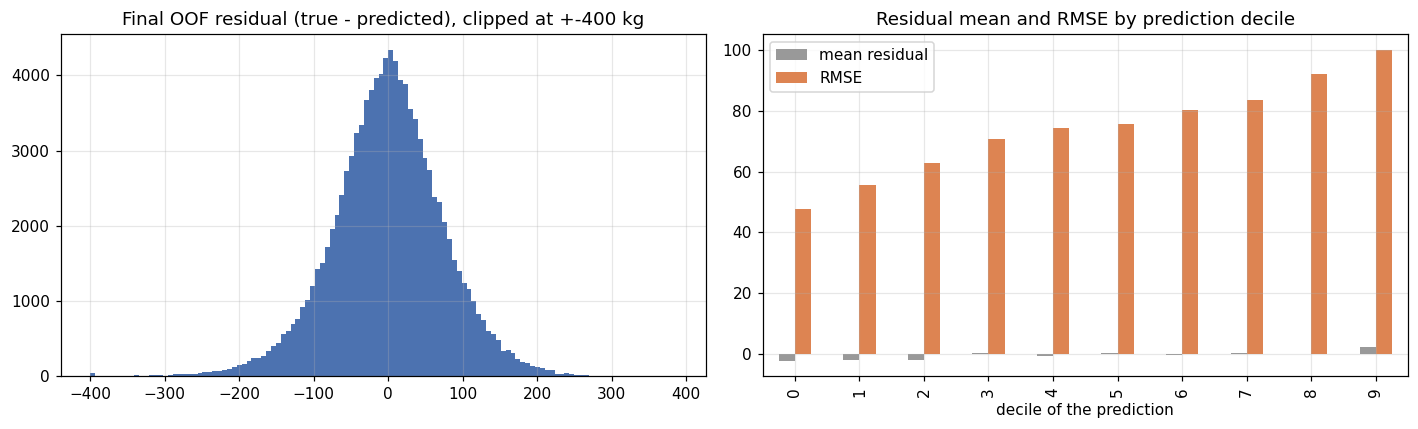

In [5]:
def athlete_key(frame, with_federation=True, extra=()):
    birth = np.floor(frame['MeetYear'] - frame['Age'] + 1e-9).astype(int).astype(str)
    key = frame['Sex'] + '|' + frame['Country'] + '|' + frame['State']
    if with_federation:
        key = key + '|' + frame['Federation']
    key = key + '|' + birth
    for column in extra:
        key = key + '|' + frame[column].astype(str)
    return key.reset_index(drop=True)


def final_residuals():
    final_ensemble_source = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    before = np.load(final_ensemble_source / 'oof_nested_blend.npy')        # Ensemble NNLS des huit modèles
    after = np.load(final_ensemble_source / 'oof_final_crossfit.npy')       # Puis correspondances d’enregistrements + Lissage combiné des résidus (coefficients cross-fittés)
    require(len(before) == n_train and len(after) == n_train, 'Longueur OOF incorrecte')
    ensemble_residuals, corrected_residuals = y - before, y - after
    print(f'RMSE locale : ensemble {rmse(y, before):.3f} → post-traitement {rmse(y, after):.3f}')
    keys_all = pd.concat([athlete_key(train), athlete_key(test)], ignore_index=True)
    appearances = keys_all.map(keys_all.value_counts()).iloc[:n_train].to_numpy()
    appearances = np.where(train['Country'].to_numpy() == 'Unknown', 0, appearances)
    age_half = ((train['Age'] * 2).round() % 2).astype(int).to_numpy()
    largest = train['Federation'].value_counts().head(8).index
    groups = {
        'Sexe × équipement': (train['Sex'] + '|' + train['Equipment']).to_numpy(),
        'Contrôle antidopage': train['Tested'].to_numpy(),
        'Tranche d’âge': pd.cut(train['Age'], [0, 18, 24, 35, 40, 50, 60, np.inf], right=False).astype(str).to_numpy(),
        'Tranche de poids': pd.cut(train['BodyweightKg'], [0, 60, 75, 90, 105, 120, 140, np.inf], right=False).astype(str).to_numpy(),
        'Année de compétition': pd.cut(train['MeetYear'], [-np.inf, 2000, 2010, 2015, 2020, np.inf], right=False).astype(str).to_numpy(),
        'Fédération (8 principales)': np.where(train['Federation'].isin(largest), train['Federation'], 'Autre'),
        'Âge en x.5': np.where(age_half == 1, 'x.5', 'Entier'),
        'Apparitions du même athlète (train+test)': pd.cut(appearances, [-1, 0, 1, 2, 5, np.inf],
                                                labels=['Nationalité inconnue', '1', '2', '3-5', '6+']).astype(str),
    }
    parts = []
    for name, key in groups.items():
        frame = pd.DataFrame({'k': np.asarray(key).astype(str), 'r0': ensemble_residuals, 'r1': corrected_residuals})
        part = frame.groupby('k').agg(effectif=('r1', 'size'), residu_moyen_ensemble=('r0', 'mean'), residu_moyen_final=('r1', 'mean'),
                                      RMSE_finale=('r1', lambda v: float(np.sqrt(np.mean(np.square(v))))))
        part.index = pd.MultiIndex.from_product([[name], part.index], names=['Groupe', 'Valeur'])
        parts.append(part)
    display(pd.concat(parts).round(2))

    big = np.abs(corrected_residuals) > 150
    print(f'|résidu| > 150 kg : {big.mean():.1%} des lignes, {np.sum(corrected_residuals[big] ** 2) / np.sum(corrected_residuals ** 2):.0%} de l’erreur quadratique')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(np.clip(corrected_residuals, -400, 400), bins=120, color='#4c72b0')
    axes[0].set_title('Final OOF residual (true - predicted), clipped at +-400 kg')
    deciles = pd.qcut(after, 10, labels=False, duplicates='drop')
    binned = pd.DataFrame({'d': deciles, 'r': corrected_residuals}).groupby('d')['r'].agg(
        ['mean', lambda v: float(np.sqrt(np.mean(np.square(v))))])
    binned.columns = ['mean residual', 'RMSE']
    binned.plot.bar(ax=axes[1], color=['#999999', '#dd8452'])
    axes[1].set_xlabel('decile of the prediction')
    axes[1].set_title('Residual mean and RMSE by prediction decile')
    plt.tight_layout()
    plt.show()


final_residuals()

Dans la plupart des groupes, le résidu moyen est à moins de 1.5 kg de zéro. Les écarts les plus nets concernent de petits groupes : femmes en Multi-ply (380 lignes) +4.3, poids de 140 kg et plus +3.9, plus de 60 ans −2.5, sportifs vus une seule fois −1.3. Le groupe Mx n'a que 9 lignes.

La RMSE va de 54 kg pour les femmes en Raw à 111 kg pour les hommes en Multi-ply. Les 5.3 % de lignes dont l'erreur dépasse 150 kg pèsent 36 % de l'erreur quadratique. Ce sont souvent des compétitions incomplètes (par exemple 155 kg au total pour un athlète de 216 kg), mais les retirer n'arrange rien (section 3).

## 2. Structure des résidus et corrections

Les variables ne disent pas le niveau de quelqu'un, mais l'apprentissage contient souvent d'autres résultats de la même personne. Pour le voir, on corrèle le résidu d'une ligne avec le résidu moyen des autres lignes de la même clé. Cette corrélation vaut environ 0.095 pour la version v2, 0.045 une fois les variables d'historique et de carrière ajoutées, et à peu près 0 après les corrections.

Pour la clé de compétition, elle passe de −0.008 à 0.037 : les corrections laissent une petite corrélation entre lignes d'une même compétition, que le second passage du lissage par paires exploite (notebook 04).

In [6]:
def athlete_residual_correlation():
    """Corrélation avec le résidu moyen des autres lignes de même clé (leave-one-out)."""
    final_ensemble_source = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    before = y - np.load(final_ensemble_source / 'oof_nested_blend.npy')
    after = y - np.load(final_ensemble_source / 'oof_final_crossfit.npy')
    known = (train['Country'] != 'Unknown').to_numpy()
    keys = {
        'A0 sexe + nationalité + État + naissance': (athlete_key(train, with_federation=False), known),
        'A1 + fédération': (athlete_key(train), known),
        'A2 + équipement': (athlete_key(train, extra=['Equipment']), known),
        'Compétition × sexe × équipement': ((train['Federation'] + '|' + train['MeetYear'].astype(str) + '|' + train['MeetCountry']
                             + '|' + train['MeetState'] + '|' + train['Sex'] + '|' + train['Equipment'])
                            .reset_index(drop=True), np.ones(n_train, dtype=bool)),
    }

    def loo_corr(residual, key, valid):
        frame = pd.DataFrame({'k': key.to_numpy(), 'r': residual})
        total = frame.groupby('k')['r'].transform('sum').to_numpy()
        count = frame.groupby('k')['r'].transform('size').to_numpy()
        mask = valid & (count > 1)
        others = (total - residual) / np.maximum(count - 1, 1)
        return float(np.corrcoef(residual[mask], others[mask])[0, 1]), int(mask.sum())

    rows = []
    for name, (key, valid) in keys.items():
        c0, n0 = loo_corr(before, key, valid)
        c1, _ = loo_corr(after, key, valid)
        rows.append({'Clé': name, 'Lignes avec une autre ligne de même clé': n0, 'Corrélation après ensemble': c0, 'Corrélation après post-traitement': c1})
    display(pd.DataFrame(rows).set_index('Clé').round(3))


athlete_residual_correlation()

,Lignes avec une autre ligne de même clé,Corrélation après ensemble,Corrélation après post-traitement
Clé,,,
Clé 1 : sexe + nationalité + État + naissance,99058,0.048,-0.014
Clé 2 : + fédération,84916,0.044,0.008
Clé 3 : + équipement,79779,0.046,0.001
Compétition × sexe × équipement,97622,-0.008,0.037


Les coefficients sont ajustés sur une moitié des groupes sexe + pays + État et évalués sur l'autre, de sorte que toutes les lignes d'une personne soient du même côté.

1. **Jumelles** : `pred + alpha × (moyenne des jumelles − pred)`, avec alpha ≈ 0.85 pour une ligne identique sur les 16 colonnes et ≈ 0.5 pour la clé à 9 colonnes.
2. **Lissage par groupes** : moyenne des résidus des autres lignes du groupe, ramenée vers zéro quand le groupe est petit, puis combinaison linéaire. Les groupes : sexe + pays + État + année de naissance, puis en ajoutant la fédération, l'équipement, la catégorie ; plus un groupe « même compétition ».

Cinq variantes sont comparées : même année de naissance ; année à ±1 ; pondération qui décroît avec l'écart d'années de compétition ; les trois ensemble, combinées linéairement ; les trois ensemble, combinées par un petit LightGBM.

In [7]:
def stage2_history():
    round1 = ARTIFACTS / '02_feature_engineering' / CACHE_CONTEXT_ABLATION
    zoo = ARTIFACTS / '03_model_selection' / 'model_zoo'
    round3 = ARTIFACTS / '02_feature_engineering' / CACHE_CAREER_ABLATION
    final = ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE
    print('1) Jumeaux (exp. 07, ensemble à trois modèles) :')
    show(read_summary(round1 / 'summary_twins.csv'))
    print('2) Lissage individuel S0 (exp. 08) sur le stacking et v2 :')
    show(read_summary(zoo / 'summary_stage2.csv'),
         ['oof_rmse', 'twins_crossfit', 'twins_athlete_crossfit', 'athlete_gain', 'beta_A0', 'beta_A1', 'beta_A2',
          'beta_A3', 'beta_M2'])
    print('3) Cinq lissages (exp. 10, ALL3 + jumeaux) :')
    show(read_summary(round3 / 'summary_stage2_variants.csv'))
    print('4) Version finale (exp. 15) :')
    show(read_summary(final / 'summary_stage2.csv'))


stage2_history()

1) Jumeaux (exp. 07, ensemble à trois modèles) :


,oof_rmse,oof_rmse_twinfix_crossfit,alpha_exact,alpha_core,test_rows_exact,test_rows_core
name,,,,,,
F0_blend3,77.956,77.701,0.866,0.57,465,54
ALL_blend3_C2,77.210,76.966,0.864,0.54,465,54


2) Lissage individuel même année (exp. 08) sur le stacking et v2 :


,oof_rmse,twins_crossfit,twins_athlete_crossfit,athlete_gain,beta_A0,beta_A1,beta_A2,beta_A3,beta_M2
base,,,,,,,,,
"08 stacking, cinq plis (global_nnls)",77.013,76.757,76.521,0.236,0.247,-0.022,0.119,0.193,-0.039
"v2 (10 plis × graines, NNLS)",77.302,77.059,76.774,0.285,0.240,-0.036,0.107,0.167,0.482


3) Cinq lissages (exp. 10, Variables finales + jumeaux) :


,n_features,crossfit_rmse,gain_vs_twins,fold1,fold2,fold3,fold4,fold5
variant,,,,,,,,
Combinaison linéaire,13,76.510,0.139,76.489,76.677,76.906,76.740,75.733
Pondération temporelle,5,76.527,0.122,76.516,76.688,76.893,76.764,75.770
Même année,5,76.539,0.109,76.503,76.693,76.938,76.766,75.792
Année ±1,5,76.544,0.105,76.514,76.707,76.947,76.749,75.799
Combinaison par LightGBM,13,76.858,-0.209,76.890,76.909,77.313,77.104,76.067


4) Version finale (exp. 15) :


,oof_rmse
step,
Ensemble (RMSE locale),76.319
+ jumeaux (cross-fitting),76.097
+ lissage combiné des résidus (coefficients croisés),75.966


Les jumelles font gagner 0.22 à 0.26 kg en local et 0.18 / 0.19 kg sur deux soumissions publiques. Le lissage gagne 0.24 kg dans l'expérience 08 et 0.29 / 0.48 kg au public. **La combinaison linéaire des trois variantes est la meilleure** ; le petit LightGBM surapprend (+0.21). Une fois les variables d'historique ajoutées, le lissage ne gagne plus que 0.13 kg : les deux se recoupent en partie.

Le lissage par groupes traite toutes les lignes d'un groupe de la même façon. Le lissage par paires (notebook 04, section 5) apprend un poids pour chaque paire et gagne encore 0.39 kg : 75.966 → 75.607 → 75.575.

## 3. Essai de nettoyage (expérience 11)

Lignes suspectes : total inférieur à 2.5 × poids chez les hommes, à 1.8 × poids chez les femmes, ou âge inférieur à 5 ans. Cela fait environ 0.25 % des lignes.

On les retire de l'apprentissage et de l'early stopping, mais on garde toute la validation. Comparaison pli par pli avec le modèle normal, puis sur les seules lignes non suspectes.

In [8]:
def cleaning_test():
    six_model_directory = ARTIFACTS / '04_final_model' / CACHE_SIX_MODEL_ENSEMBLE
    ratio = y / train['BodyweightKg'].to_numpy(dtype='float64')
    suspicious = (np.where(train['Sex'].to_numpy() == 'M', ratio < 2.5, ratio < 1.8)
                  | (train['Age'].to_numpy(dtype='float64') < 5))
    print(f'Lignes suspectes : {int(suspicious.sum())} ({suspicious.mean():.2%})')
    rows = []
    for model in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]:
        base_all, clean_all, base_normal, clean_normal = [], [], [], []
        for k in range(1, N_FOLDS + 1):
            base_path = six_model_directory / f'{model}__s{SEED}__fold{k}.npz'
            clean_path = six_model_directory / f'clean_{model}__s{SEED}__fold{k}.npz'
            if not (base_path.is_file() and clean_path.is_file() and clean_path.with_suffix('.json').is_file()):
                continue                                   # Comme exp. 11 : npz et json requis pour un résultat complet
            base, clean = np.load(base_path), np.load(clean_path)
            idx = base['valid_idx']
            require(np.array_equal(idx, clean['valid_idx']), 'Lignes de validation différentes entre nettoyage et référence')
            normal = ~suspicious[idx]
            base_all.append(rmse(y[idx], base['val']))
            clean_all.append(rmse(y[idx], clean['val']))
            base_normal.append(rmse(y[idx][normal], base['val'][normal]))
            clean_normal.append(rmse(y[idx][normal], clean['val'][normal]))
        if base_all:
            delta = np.array(clean_all) - np.array(base_all)
            rows.append({'Modèle': model, 'Plis terminés': len(base_all), 'Référence : toute la validation': np.mean(base_all),
                         'Train nettoyé : toute la validation': np.mean(clean_all), 'Δ': delta.mean(),
                         'Plis améliorés': int((delta < 0).sum()), 'Référence : lignes non suspectes': np.mean(base_normal),
                         'Train nettoyé : lignes non suspectes': np.mean(clean_normal)})
    if rows:
        display(pd.DataFrame(rows).set_index('Modèle').round(3))


cleaning_test()

Lignes suspectes : 265 (0.25%)


,Plis terminés,Référence : toute la validation,Train nettoyé : toute la validation,Δ,Plis améliorés,Référence : lignes non suspectes,Train nettoyé : lignes non suspectes
Modèle,,,,,,,
LightGBM,5,77.708,77.751,0.043,2,76.821,76.787
XGBoost,5,78.457,78.519,0.063,2,77.545,77.519
CatBoost,5,77.497,77.577,0.081,1,76.627,76.620


Les trois modèles sont **moins bons de 0.04 à 0.08 kg**, avec au mieux 2 plis améliorés sur 5. Sur les lignes non suspectes seules, le gain est de 0.01 à 0.03 kg. Comme le test contient lui aussi des résultats incomplets, on garde toutes les lignes.

## 4. Ce qui n'a pas marché

| Piste | Résultat | Où |
|---|---|---|
| Niveau du sportif et de la compétition à partir des totaux | +0.14 / +0.52, public moins bon aussi | 02, série 4 |
| Contexte enrichi, divisions, coefficient DOTS (dans la combinaison) | +0.00 à +0.05 | 02, série 2 |
| Déplacements seuls | −0.04, sous le seuil | 02, série 1 |
| Target encoding grossier (sexe × équipement × catégorie) | +0.27 | premiers essais |
| Fréquences, interaction sexe × équipement, année de naissance | ±0.05 | premiers essais |
| TabPFN, forêt aléatoire, ExtraTrees, EBM, Ridge | 3 à 7 kg derrière, poids nul | 03, section 5 |
| NNLS par groupe, méta-modèle de résidus | pas mieux que le NNLS global | 03, section 3 |
| Lissage combiné par LightGBM | surapprentissage, +0.21 | section 2 |
| Retrait des lignes suspectes | +0.04 à +0.08 | section 3 |
| id comme variable | ordre aléatoire | 01, section 7 |
| Cible log | biais au retour en kg | — |
| Base OpenPowerlifting | contient les lignes du test : ce serait une fuite, on ne l'utilise pas | — |

## 5. Score local et score public

Toutes les soumissions qui ont un score local sont comparées à leur score public. Ensuite, pour savoir ce que vaut un écart au public, on tire au hasard 13 500 lignes parmi les prédictions hors pli, comme le fait le classement public avec le test.

,local,public,public - local
submission,,,
v1,77.775,78.000,0.225
v2,77.302,77.799,0.497
v2 + jumelles,77.060,77.604,0.544
variables de départ + jumelles,77.701,77.947,0.246
série 1 + CatBoost régularisé,77.210,77.337,0.127
série 1 + CatBoost régularisé + jumelles,76.966,77.158,0.192
exp. 08 : plus de modèles,77.013,77.207,0.194
exp. 08 + jumelles,76.757,77.018,0.261
exp. 08 + jumelles + lissage,76.521,76.731,0.210


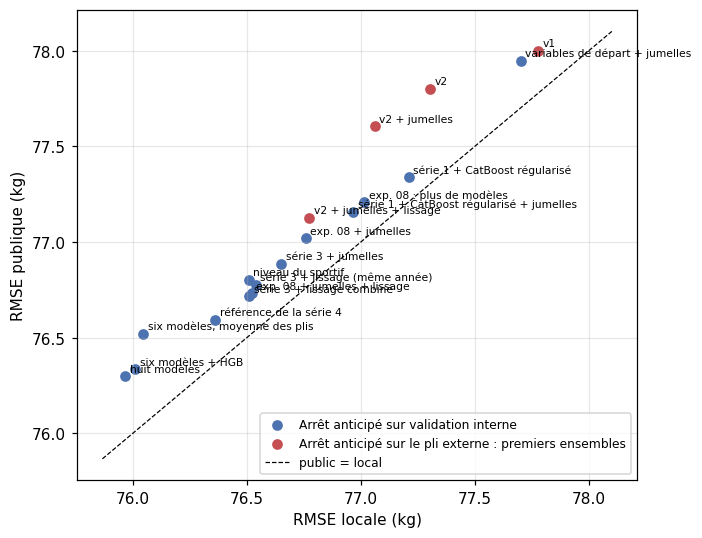

Corrélation de Spearman local/public avec arrêt anticipé interne : 0.97
105 000 lignes : ensemble final 75.966, ensemble avec HistGradientBoosting 76.010, écart -0.045
Tirages de 13 500 lignes : écart-type RMSE 0.588 ; écart-type de la différence 0.026 ; ordre inversé dans 4% des tirages
Écart public observé entre ensemble final et ensemble avec HistGradientBoosting : -0.036


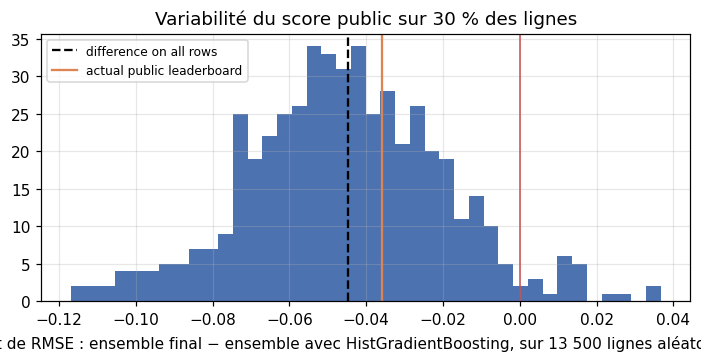

In [9]:
def leaderboard_analysis():
    history = pd.DataFrame([
        (ENSEMBLE_INITIAL, 77.775, 78.0), (ENSEMBLE_TEN_FOLD, 77.302, 77.799), (HISTORY_TEN_FOLD_MATCHING, 77.060, 77.604),
        (HISTORY_WEIGHT_CLASS_MATCHING, 77.701, 77.947), (HISTORY_CONTEXT_REGULARIZED, 77.210, 77.337), (HISTORY_CONTEXT_REGULARIZED_MATCHING, 76.966, 77.158),
        (HISTORY_MODEL_STACKING, 77.013, 77.207), (HISTORY_STACKING_MATCHING, 76.757, 77.018), (HISTORY_STACKING_RESIDUAL_SMOOTHING, 76.521, 76.731),
        (HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING, 76.774, 77.125), (HISTORY_FINAL_FEATURES_MATCHING, 76.649, 76.884),
        (HISTORY_EXACT_BIRTHYEAR_SMOOTHING, 76.539, 76.775), (HISTORY_COMBINED_RESIDUAL_SMOOTHING, 76.510, 76.716), (HISTORY_SIX_MODEL_FOLD_AVERAGE, 76.044, 76.520),
        (HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE, 76.010, 76.334), (HISTORY_FINAL_FEATURES_REFERENCE, 76.361, 76.592), (HISTORY_ATHLETE_PERFORMANCE, 76.508, 76.802),
        (HISTORY_FINAL_ENSEMBLE, 75.966, 76.298),
    ], columns=['submission', 'cv', 'public'])
    history['public - cv'] = history['public'] - history['cv']
    display(history.rename(columns={'cv': 'local', 'public - cv': 'public - local'}).set_index('submission').round(3))
    early = history['submission'].isin([ENSEMBLE_INITIAL, ENSEMBLE_TEN_FOLD, HISTORY_TEN_FOLD_MATCHING, HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING])   # Early stopping externe
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.scatter(history.loc[~early, 'cv'], history.loc[~early, 'public'], color='#4c72b0', label='Arrêt anticipé sur validation interne')
    ax.scatter(history.loc[early, 'cv'], history.loc[early, 'public'], color='#c44e52', label='Arrêt anticipé sur le pli externe : premiers ensembles')
    for _, row in history.iterrows():
        ax.annotate(presentation_label(row['submission']), (row['cv'], row['public']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    lims = [history[['cv', 'public']].min().min() - 0.1, history[['cv', 'public']].max().max() + 0.1]
    ax.plot(lims, lims, color='black', lw=0.8, ls='--', label='public = local')
    ax.set_xlabel('RMSE locale (kg)')
    ax.set_ylabel('RMSE publique (kg)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"Corrélation de Spearman local/public avec arrêt anticipé interne : "
          f"{history.loc[~early, ['cv', 'public']].corr(method='spearman').iloc[0, 1]:.2f}")


def public_noise():
    """Tirer 13 500 lignes OOF et comparer l’ensemble final à l’ensemble avec HistGradientBoosting, comme approximation du public."""
    histogram_ensemble_predictions = np.load(ARTIFACTS / '03_model_selection' / 'model_compare' / 'oof_final_crossfit.npy')
    final_ensemble_source = np.load(ARTIFACTS / '04_final_model' / CACHE_FINAL_ENSEMBLE / 'oof_final_crossfit.npy')
    rng = np.random.default_rng(SEED)
    single, diff = [], []
    for _ in range(500):
        idx = rng.choice(n_train, 13500, replace=False)
        a, b = rmse(y[idx], histogram_ensemble_predictions[idx]), rmse(y[idx], final_ensemble_source[idx])
        single.append(b)
        diff.append(b - a)
    diff = np.array(diff)
    public_gap = 76.298 - 76.334                       # Scores publics archivés : ensemble final à huit candidats 76.298, ensemble avec HistGradientBoosting 76.334
    print(f'105 000 lignes : ensemble final {rmse(y, final_ensemble_source):.3f}, ensemble avec HistGradientBoosting {rmse(y, histogram_ensemble_predictions):.3f}, écart {rmse(y, final_ensemble_source) - rmse(y, histogram_ensemble_predictions):+.3f}')
    print(f'Tirages de 13 500 lignes : écart-type RMSE {np.std(single):.3f} ; écart-type de la différence {np.std(diff):.3f} ; '
          f'ordre inversé dans {np.mean(diff > 0):.0%} des tirages')
    print(f'Écart public observé entre ensemble final et ensemble avec HistGradientBoosting : {public_gap:+.3f}')
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.hist(diff, bins=40, color='#4c72b0')
    ax.axvline(rmse(y, final_ensemble_source) - rmse(y, histogram_ensemble_predictions), color='black', ls='--', label='difference on all rows')
    ax.axvline(public_gap, color='#dd8452', lw=1.5, label='actual public leaderboard')
    ax.axvline(0, color='#c44e52', lw=1)
    ax.set_xlabel('Écart de RMSE : ensemble final − ensemble avec HistGradientBoosting, sur 13 500 lignes aléatoires (kg)')
    ax.set_title('Variabilité du score public sur 30 % des lignes')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


leaderboard_analysis()
public_noise()

Depuis l'expérience 07 (early stopping interne), le classement local et le classement public sont presque les mêmes : corrélation de rang 0.97. Le score public est en général 0.2 à 0.3 kg au-dessus du local.

Dans la simulation, le score d'une soumission varie beaucoup d'un tirage à l'autre (écart-type 0.59 kg), mais la différence entre deux soumissions proches très peu (0.03 kg). Autrement dit, le niveau absolu du score public dépend du tirage, alors que l'écart entre deux soumissions est fiable.

Exemple : la version à huit modèles gagne 0.045 kg en local sur la précédente et 0.036 kg au public ; dans la simulation l'ordre s'inverse dans 4 % des tirages.

## 6. Bilan

Ce qui a le plus compté : repérer la structure des données (précision de saisie, jumelles, autres résultats du même sportif), moyenner plusieurs graines et réentraîner sur toutes les lignes. Les cibles DOTS et IPF GL complètent bien les modèles en kg. Les variables sans cible ne progressent plus après la troisième série, et les totaux connus servent mieux après les modèles que dedans.

Résultat : 77.775 en local et 78.0 au public pour la première version ; 75.966 / 76.298 pour les huit modèles ; **75.575 / 76.030** avec le lissage par paires.